# 2. RQ1: Adoção e autoria por agentes

**Pergunta:** o formato está se espalhando? E quem escreve as skills: pessoas ou os próprios agentes de IA?

**Por que importa:** se boa parte das instruções que os agentes seguem foi escrita por agentes, o ecossistema se retroalimenta, e ninguém revisa um texto que nenhuma pessoa escreveu inteiramente.

**Como medimos:** (1) contamos novas skills por mês desde o lançamento (out/2025); (2) olhamos o primeiro commit de cada skill: se ele tem um trailer `Co-authored-by: Claude` (ou Cursor, Copilot…) ou foi feito por uma conta bot, contamos como escrita por assistente. A margem de erro é o intervalo de confiança de Wilson a 95%.

---

### English summary

**Methodology step 3: quantitative descriptive analysis.**

* RQ1.1 How fast did the format spread after October 2025?
* RQ1.2 What share of skills were first committed with an AI assistant credited as co-author (a `Co-authored-by` trailer) or by a bot account?

Proportions are reported with 95% Wilson confidence intervals.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("GITSKILLS_DB", str(ROOT / "data/raw/agent_skills_release.db"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 80)
from gitskills import clean, db, reuse, adoption, patterns
from gitskills.plots import save, save_table
%matplotlib inline
print("database:", os.environ["GITSKILLS_DB"])
from statsmodels.stats.proportion import proportion_confint

database: /Users/cleber/Documents/gitskills-mc/code/data/raw/agent_skills_release.db


In [2]:
skills = clean.strict(clean.load_skills())
cov = adoption.history_coverage(skills)
complete = cov.loc[cov["share"] >= 0.9, "location_class"].tolist()
print("location classes with complete history:", complete)

location classes with complete history: ['canonical']


## 2.1 Novas skills por mês
**Objetivo:** medir o ritmo de adoção. Usamos só `canonical`, o único local com histórico completo (notebook 01, §1.5); misturar locais amostrados distorceria a curva.

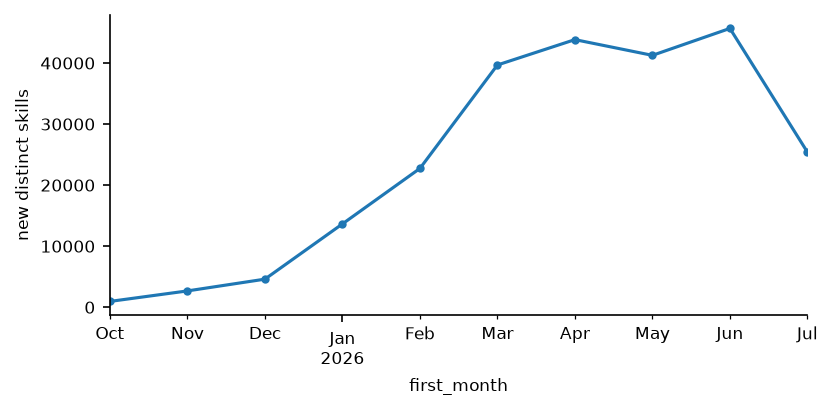

,first_month,new_skills
0,2025-10,953
1,2025-11,2674
2,2025-12,4601
3,2026-01,13649
4,2026-02,22738
5,2026-03,39682
6,2026-04,43836
7,2026-05,41262
8,2026-06,45672
9,2026-07,25411


In [3]:
std = skills[skills["location_class"].isin(complete)]
cohorts = adoption.monthly_cohorts(std)
ax = cohorts.set_index("first_month")["new_skills"].plot(marker=".", figsize=(6, 2.6))
ax.set_ylabel("new distinct skills"); plt.show()
cohorts

**O que os dados mostram:** de **953** novas skills em out/2025 para **45.672** em jun/2026, cerca de **48 vezes** em oito meses. O crescimento acelera até mar/2026 e depois se estabiliza em ~40–45 mil por mês. Julho cai porque o snapshot foi coletado no meio do mês, não por queda de adoção.

## 2.2 Autoria por assistente
**Objetivo:** estimar que fração das skills foi criada com um agente de IA registrado como coautor.

In [4]:
h = skills[skills["has_history"]].copy()
h["ai_first"] = h["first_commit_ai"].notna() | h["first_commit_bot"]
k, n = int(h["ai_first"].sum()), len(h)
lo, hi = proportion_confint(k, n, method="wilson")
print(f"first commit by an assistant or bot: {k:,}/{n:,} = {k/n:.1%} (95% CI {lo:.1%}-{hi:.1%})")

first commit by an assistant or bot: 126,424/396,247 = 31.9% (95% CI 31.8%-32.1%)


**O que os dados mostram:** **31,9%** (IC 95%: 31,8–32,1%) das skills com histórico nasceram em um commit assinado por um assistente ou bot. **Cerca de uma em cada três skills foi escrita com um agente.**

In [5]:
h["first_commit_ai"].value_counts().rename("skills").to_frame()

,skills
first_commit_ai,
claude,116609
cursor,3311
copilot,2435
codex,250
devin,51
gemini,45
chatgpt,18
openai,17
aider,15


**O que os dados mostram:** o Claude responde por **95%** desses casos (116.609), seguido de longe por Cursor (3.311) e Copilot (2.435). Isso reflete tanto a origem do formato (Claude Code) quanto o fato de o Claude adicionar o trailer por padrão; outras ferramentas podem estar sub-representadas.

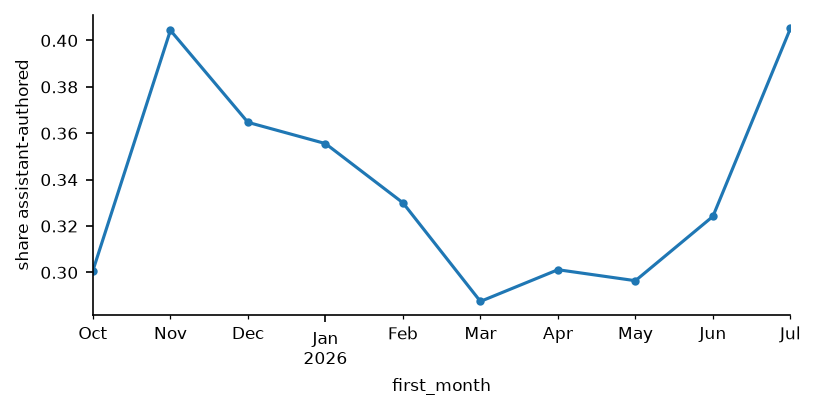

,skills,share
first_month,,
2025-10,1107,0.300813
2025-11,2928,0.404372
2025-12,5684,0.364708
2026-01,18543,0.355552
2026-02,35747,0.330014
2026-03,68850,0.287495
2026-04,71831,0.301165
2026-05,77024,0.296427
2026-06,76801,0.324162


In [6]:
by_month = h.groupby("first_month")["ai_first"].agg(skills="size", share="mean")
ax = by_month["share"].plot(marker=".", figsize=(6, 2.6)); ax.set_ylabel("share assistant-authored"); plt.show()
by_month

## 2.3 Quem escreve as novas skills, mês a mês
**Objetivo:** juntar as duas medidas anteriores em um só gráfico: o total de novas skills por mês (linha) e como esse total se divide entre skills sem assistente creditado, Claude e outros assistentes ou bots (barras). Como Cursor, Copilot e bots somam menos de 1% e sumiriam nas barras, o painel (b) mostra esses grupos na própria escala. Usamos só `canonical` (histórico completo), como em §2.1.

**Atenção:** "sem assistente creditado" não significa escrita manual: o trailer `Co-authored-by` pode ter sido removido.

  table  -> results/tables/rq1_authorship_by_assistant_month.csv


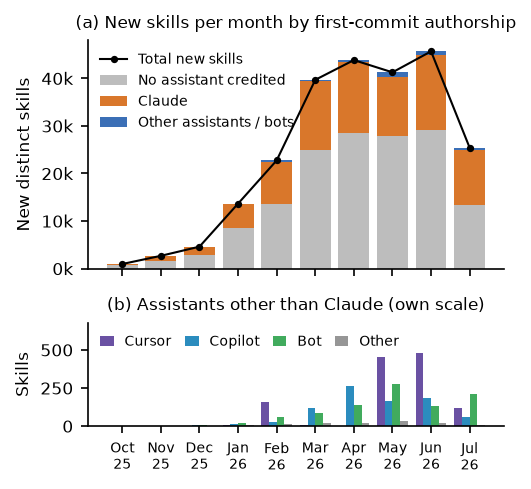

canonical skills with an assistant or bot credited: 37.3%


first_commit_ai,claude,cursor,copilot,other assistant,bot,none
first_month,,,,,,
2025-10,288,0,0,0,0,665
2025-11,1115,0,1,1,3,1554
2025-12,1666,1,5,0,9,2920
2026-01,5177,8,13,6,21,8424
2026-02,8940,161,29,16,61,13531
2026-03,14462,8,121,18,85,24988
2026-04,14913,3,267,19,140,28494
2026-05,12431,454,167,31,279,27900
2026-06,15788,478,185,20,135,29066


In [7]:
auth = adoption.authorship_by_assistant(std)
save_table(auth.reset_index(), "rq1_authorship_by_assistant_month")
import matplotlib.ticker as mticker
labels = [pd.Period(m).strftime("%b\n%y") for m in auth.index]
x = np.arange(len(auth))
fig, (a, b) = plt.subplots(2, 1, figsize=(3.5, 3.3), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
others = auth[["cursor", "copilot", "other assistant", "bot"]].sum(axis=1)
a.bar(x, auth["none"], color="#bdbdbd", label="No assistant credited")
a.bar(x, auth["claude"], bottom=auth["none"], color="#d9772b", label="Claude")
a.bar(x, others, bottom=auth["none"] + auth["claude"], color="#3b6fb6", label="Other assistants / bots")
a.plot(x, auth.sum(axis=1), color="black", marker="o", ms=2.5, lw=1, label="Total new skills")
a.set_ylabel("New distinct skills"); a.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
a.legend(frameon=False, fontsize=6.5, loc="upper left"); a.set_title("(a) New skills per month by first-commit authorship", fontsize=8)
for i, (col, c) in enumerate([("cursor", "#6a51a3"), ("copilot", "#2b8cbe"), ("bot", "#41ab5d"), ("other assistant", "#969696")]):
    b.bar(x + (i - 1.5) * 0.2, auth[col], width=0.2, color=c, label={"other assistant": "Other"}.get(col, col.capitalize()))
b.set_ylabel("Skills"); b.set_ylim(0, 680)
b.legend(frameon=False, fontsize=6.5, ncol=4, loc="upper left", handlelength=1, columnspacing=1)
b.set_title("(b) Assistants other than Claude (own scale)", fontsize=8)
b.set_xticks(x); b.set_xticklabels(labels, fontsize=6.5)
for ax in (a, b): ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(ROOT / f"results/figures/rq1_authorship_by_month.{ext}", dpi=300, bbox_inches="tight")
plt.show()
share = 1 - auth["none"].sum() / auth.values.sum()
print(f"canonical skills with an assistant or bot credited: {share:.1%}")
auth

**O que os dados mostram:** em `.claude/skills/`, **37,3%** das novas skills têm assistente ou bot creditado (acima dos 31,9% do conjunto geral). O Claude domina todos os meses. Os outros assistentes só aparecem a partir de fev/2026 e ficam abaixo de 500 skills por mês: Cursor tem picos em mai–jun/2026 e Copilot cresce a partir de mar/2026. Esta é a **Fig. 1** do artigo.

**O que os dados mostram:** a fração fica entre **29% e 40%** em todos os meses, sem tendência clara de queda ou alta. A autoria por agentes não é uma fase inicial: acompanha o crescimento do ecossistema.

## Conclusão da RQ1
* O ecossistema cresceu cerca de **48×** em oito meses.
* **Cerca de 1 em cada 3** skills foi criada com um agente como coautor, quase sempre o Claude, e essa fração é estável no tempo.

**Limitações:** é um **limite inferior** (só conta quem manteve o trailer `Co-authored-by`); vale para as 396.247 skills com histórico, concentradas em `.claude/skills/`.

**Próximo passo:** se as skills são criadas tão rápido, de onde vêm? O notebook 03 mostra que boa parte vem de cópia.